<a href="https://colab.research.google.com/github/Bvsrkrishna/Data-Analyst-Projects/blob/main/EDA1_App_Insights_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA01 - App Insights Analysis (Google Play Store)
Python (pandas) answers to the 25 'App Insights Unlocked' questions. Data: `googleplaystore.csv` (Kaggle). Each question has the code, its output, and a one-line answer.

> The EDA01 Google Doc could not be opened here, so the questions are the 25 from the App Insights (Power BI) document, which has the same title. If your EDA01 questions differ, send the doc as PDF.

## Step 1 - Load and clean the data

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt


raw = pd.read_csv('google playstore.csv')
raw

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,7-Jan-18,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15-Jan-18,2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,1-Aug-18,1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,8-Jun-18,Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,20-Jun-18,1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,25-Jul-17,1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,6-Jul-18,1,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,20-Jan-17,1,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,19-Jan-15,Varies with device,Varies with device


In [7]:

df = raw[raw["Category"] != "1.9"].copy()
df["Type"] = df["Type"].fillna("Free")
df["Reviews"] = df["Reviews"].astype(int)
df["Installs"] = df["Installs"].str.replace("[+,]", "", regex=True).astype("int64")
df["Price"] = df["Price"].str.replace("$", "", regex=False).astype(float)
def size_mb(s):
    if s == "Varies with device": return np.nan
    return float(s[:-1]) if s.endswith("M") else float(s[:-1]) / 1024
df["Size_MB"] = df["Size"].map(size_mb)
df["Category"] = df["Category"].str.replace("_", " ").str.title()
df["Last Updated"] = pd.to_datetime(df["Last Updated"], format="mixed")
df = df.sort_values(["App", "Reviews"], ascending=[True, False]).drop_duplicates("App").reset_index(drop=True)
rated = df.dropna(subset=["Rating"])
print("rows before:", len(raw), "| unique apps after cleaning:", len(df), "| rated apps:", len(rated))

rows before: 10841 | unique apps after cleaning: 9659 | rated apps: 8196


## Basic questions

### Q1. Average rating of apps

In [8]:
print(round(rated['Rating'].mean(), 2))

4.17


**Answer:** Average rating = 4.17 (across 8,196 rated apps; 1,463 apps have no rating and are excluded).

### Q2. Number of unique categories

In [9]:
print(df['Category'].nunique())

33


**Answer:** 33 unique categories.

### Q3. Distribution of app sizes

count    8431.00
mean       20.40
std        21.83
min         0.01
25%         4.60
50%        12.00
75%        28.00
max       100.00
Name: Size_MB, dtype: float64
Size_MB
[0, 5)         2263
[5, 10)        1529
[10, 20)       1548
[20, 30)       1107
[30, 50)       1072
[50, 100)       898
[100, 1000)      14
Name: count, dtype: int64


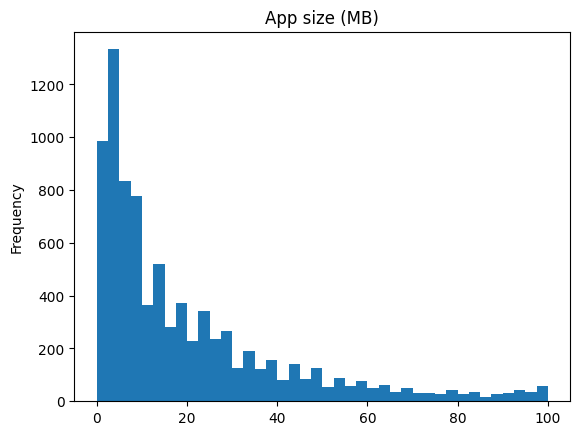

In [10]:
print(df['Size_MB'].describe().round(2))
print(pd.cut(df['Size_MB'], [0,5,10,20,30,50,100,1000], right=False).value_counts().sort_index())
df['Size_MB'].plot.hist(bins=40, title='App size (MB)'); plt.show()

**Answer:** Median size 12 MB, mean 20.4 MB (range 0.01-100 MB). 45% of apps are under 10 MB; only 0.2% exceed 100 MB. (1,228 apps are 'Varies with device' and have no size.)

### Q4. Free vs paid apps

In [11]:
print(df['Type'].value_counts()); print(df['Type'].value_counts(normalize=True).mul(100).round(2))

Type
Free    8905
Paid     754
Name: count, dtype: int64
Type
Free    92.19
Paid     7.81
Name: proportion, dtype: float64


**Answer:** Free = 8,905 (92.19%); Paid = 754 (7.81%).

### Q5. Most common content rating

In [12]:
print(df['Content Rating'].value_counts().head()); print(df['Content Rating'].value_counts(normalize=True).mul(100).round(2).head(3))

Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Name: count, dtype: int64
Content Rating
Everyone      81.82
Teen          10.73
Mature 17+     4.07
Name: proportion, dtype: float64


**Answer:** 'Everyone' - 7,903 apps (81.82%), followed by Teen (10.73%).

### Q6. Top 5 most installed apps (ties broken by reviews)

In [13]:
print(df.sort_values(['Installs','Reviews'], ascending=False).head(5)[['App','Category','Installs','Reviews','Rating']])

                                           App       Category    Installs   Reviews  Rating
4328                                  Facebook         Social  1000000000  78158306     4.1
9041                        WhatsApp Messenger  Communication  1000000000  69119316     4.4
5399                                 Instagram         Social  1000000000  66577446     4.5
6165  Messenger – Text and Video Chat for Free  Communication  1000000000  56646578     4.0
8079                            Subway Surfers           Game  1000000000  27725352     4.5


**Answer:** Facebook, WhatsApp Messenger, Instagram, Messenger – Text and Video Chat for Free, Subway Surfers - all with 1,000,000,000+ installs. NOTE: 20 apps tie at 1B+ installs; these 5 are ordered by review count as the tie-breaker.

### Q7. Apps with rating 4.0 and above

In [14]:
n=(df['Rating']>=4).sum(); print(n, round(n/len(rated)*100,1), '% of rated apps')

6287 76.7 % of rated apps


**Answer:** 6,287 apps have rating >= 4.0 (76.71% of rated apps). Strictly above 4.0: 5,774.

### Q8. Average reviews, free vs paid

In [15]:
print(df.groupby('Type')['Reviews'].mean().round(0))

Type
Free    234421.0
Paid      8748.0
Name: Reviews, dtype: float64


**Answer:** Free apps average 234,421 reviews; paid apps average 8,748 (free apps get about 27x more).

### Q9. Average size by category

In [16]:
print(df.groupby('Category')['Size_MB'].mean().round(1).sort_values(ascending=False))

Category
Game                   41.7
Family                 27.3
Travel And Local       24.2
Sports                 24.1
Entertainment          23.7
Parenting              22.5
Health And Fitness     20.7
Food And Drink         20.5
Auto And Vehicles      20.0
Medical                19.2
Education              18.7
Finance                17.4
Maps And Navigation    16.4
House And Home         16.2
Social                 16.0
Video Players          15.8
Dating                 15.7
Photography            15.7
Shopping               15.5
Lifestyle              14.8
Events                 14.0
Business               13.9
Comics                 13.8
Beauty                 13.8
Books And Reference    13.1
Weather                12.7
News And Magazines     12.5
Productivity           12.3
Art And Design         12.2
Communication          11.3
Personalization        11.2
Libraries And Demo     10.6
Tools                   8.8
Name: Size_MB, dtype: float64


**Answer:** Game apps are the largest (41.66 MB), then Family (27.31 MB) and Travel And Local (24.2 MB). Smallest: Tools (8.77 MB).

### Q10. Apps last updated in 2018

In [17]:
print((df['Last Updated'].dt.year == 2018).sum())

6287


**Answer:** 6,287 apps were last updated in 2018 (65% of the dataset).

## Medium questions

### Q1. Correlation between installs and rating

In [18]:
print('Pearson :', round(rated['Installs'].corr(rated['Rating']), 4))
print('Log-installs:', round(np.log10(rated['Installs'].replace(0, np.nan)).corr(rated['Rating']), 4))
print('Spearman:', round(rated['Installs'].corr(rated['Rating'], method='spearman'), 4))

Pearson : 0.0402
Log-installs: 0.0843
Spearman: 0.0272


**Answer:** Pearson r = 0.0402 (log-installs r = 0.0843, Spearman = 0.0272): essentially NO correlation. Popular apps are not noticeably better rated.

### Q2. Categories with the highest average rating

In [19]:
r=rated.groupby('Category')['Rating'].agg(['mean','count']).round(3).sort_values('mean', ascending=False); print(r.head(10)); print(r.tail(3))

                      mean  count
Category                         
Events               4.436     45
Art And Design       4.359     59
Education            4.355    106
Books And Reference  4.345    169
Personalization      4.332    298
Parenting            4.300     50
Beauty               4.279     42
Social               4.247    203
Game                 4.245    899
Weather              4.243     72
                      mean  count
Category                         
Tools                4.040    720
Maps And Navigation  4.036    118
Dating               3.980    133


**Answer:** Highest average rating: Events (4.44), Art And Design (4.36), Education (4.36), Books And Reference (4.34), Personalization (4.33). Lowest: Dating (3.98).

### Q3. Price vs average rating (paid apps)

In [20]:
paid=rated[rated['Price']>0]
bands=pd.cut(paid['Price'], [0,1,2,5,10,50,1000], labels=['$0-1','$1-2','$2-5','$5-10','$10-50','$50+'])
print(paid.groupby(bands, observed=True)['Rating'].agg(['mean','count']).round(3))
print('free vs paid:', rated.groupby('Type')['Rating'].mean().round(3).to_dict())
print('price-rating correlation (paid):', round(paid['Price'].corr(paid['Rating']), 4))

         mean  count
Price               
$0-1    4.301    106
$1-2    4.292    101
$2-5    4.264    282
$5-10   4.259     58
$10-50  4.215     39
$50+    3.912     16
free vs paid: {'Free': 4.166, 'Paid': 4.262}
price-rating correlation (paid): -0.114


**Answer:** Among paid apps the rating falls slightly as price rises (correlation -0.114): 4.30 for $0-1 down to 3.91 for $50+. Overall, paid apps (4.26) rate slightly higher than free apps (4.17).

### Q4. Rating distribution across content ratings

                 count   mean  median  min  max
Content Rating                                 
Adults only 18+      3  4.300     4.5  3.8  4.6
Everyone          6618  4.166     4.3  1.0  5.0
Everyone 10+       305  4.226     4.3  1.8  5.0
Mature 17+         357  4.122     4.2  1.0  5.0
Teen               912  4.226     4.3  2.0  5.0
Unrated              1  4.100     4.1  4.1  4.1


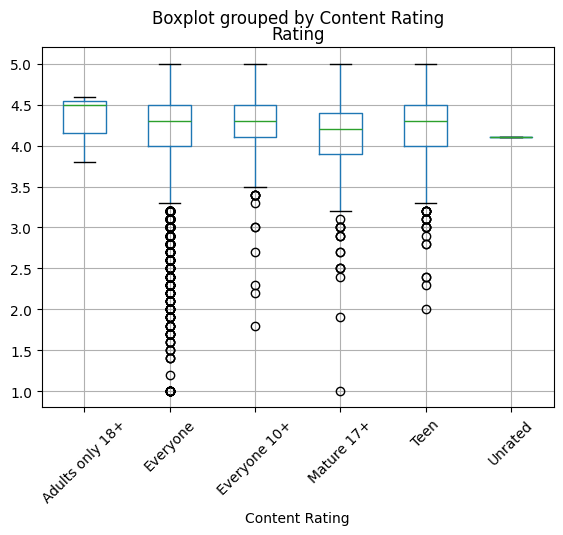

In [21]:
print(rated.groupby('Content Rating')['Rating'].agg(['count','mean','median','min','max']).round(3))
rated.boxplot(column='Rating', by='Content Rating', rot=45); plt.show()

**Answer:** Ratings are very similar across content ratings (means 4.12-4.30). Mature 17+ is lowest (4.12); Teen and Everyone 10+ are highest among sizeable groups (4.23 / 4.23).

### Q5. Genres with most apps over 1M installs

In [22]:
print(df[df['Installs']>=1_000_000].groupby('Genres').size().sort_values(ascending=False).head(10))

Genres
Tools               274
Action              180
Photography         173
Entertainment       154
Productivity        147
Communication       140
Sports              124
Health & Fitness    112
Personalization     110
Arcade              109
dtype: int64


**Answer:** Genres with most apps at 1M+ installs: Tools (274), Action (180), Photography (173), Entertainment (154), Productivity (147). (Counted as Installs >= 1,000,000, i.e. the '1,000,000+' bucket and above.)

### Q6. How often are apps updated?

In [23]:
latest=df['Last Updated'].max(); days=(latest-df['Last Updated']).dt.days
print('newest date:', latest.date(), '| average days since update:', round(days.mean(),1), '| median:', days.median())
print(pd.cut(days,[-1,30,90,180,365,730,5000]).value_counts(normalize=True).sort_index().mul(100).round(1))

newest date: 2018-08-08 | average days since update: 281.0 | median: 96.0
Last Updated
(-1, 30]       30.4
(30, 90]       18.9
(90, 180]      12.0
(180, 365]     13.7
(365, 730]     12.5
(730, 5000]    12.5
Name: proportion, dtype: float64


**Answer:** The file stores only ONE 'Last Updated' date per app, so the gap between consecutive updates cannot be computed. Closest valid measure: average time since last update = 281 days (median 96) measured to the newest date in the data (2018-08-08). 30.4% of apps were updated within 30 days.

### Q7. Impact of app size on installs

In [24]:
s=df.dropna(subset=['Size_MB'])
print('corr:', round(s['Size_MB'].corr(s['Installs']),4), '| log corr:', round(s['Size_MB'].corr(np.log10(s['Installs'].replace(0,np.nan))),4))
print(s.groupby(pd.cut(s['Size_MB'],[0,5,10,20,50,100,1000],right=False), observed=True)['Installs'].agg(['mean','median','count']).round(0))

corr: 0.1342 | log corr: 0.2991
                   mean     median  count
Size_MB                                  
[0, 5)         765703.0     5000.0   2263
[5, 10)       1617108.0    50000.0   1529
[10, 20)      4029718.0    50000.0   1548
[20, 50)      4235803.0   100000.0   2179
[50, 100)    12901970.0  1000000.0    898
[100, 1000)  14501107.0  5000000.0     14


**Answer:** Larger apps have more installs: correlation 0.1342 (0.30 on log scale). Median installs rise from 5,000 (<5 MB) to 1,000,000 (50-100 MB).

### Q8. Apps with the most reviews and their ratings

In [25]:
print(df.sort_values('Reviews', ascending=False).head(10)[['App','Category','Reviews','Rating','Installs']])

                                                    App       Category   Reviews  Rating    Installs
4328                                           Facebook         Social  78158306     4.1  1000000000
9041                                 WhatsApp Messenger  Communication  69119316     4.4  1000000000
5399                                          Instagram         Social  66577446     4.5  1000000000
6165           Messenger – Text and Video Chat for Free  Communication  56646578     4.0  1000000000
2564                                     Clash of Clans           Game  44893888     4.6   100000000
2573            Clean Master- Space Cleaner & Antivirus          Tools  42916526     4.7   500000000
8079                                     Subway Surfers           Game  27725352     4.5  1000000000
9225                                            YouTube  Video Players  25655305     4.3  1000000000
7721  Security Master - Antivirus, VPN, AppLock, Boo...          Tools  24900999     4.7   

**Answer:** Most-reviewed: Facebook (78,158,306 reviews, rating 4.1), WhatsApp Messenger (69,119,316 reviews, rating 4.4), Instagram (66,577,446 reviews, rating 4.5), Messenger – Text and Video Chat for Free (56,646,578 reviews, rating 4.0) ... All top-10 apps have ratings of 4.0-4.7.

### Q9. Content rating mix: free vs paid

In [26]:
print(pd.crosstab(df['Content Rating'], df['Type'])); print(pd.crosstab(df['Content Rating'], df['Type'], normalize='columns').mul(100).round(2))

Type             Free  Paid
Content Rating             
Adults only 18+     3     0
Everyone         7250   653
Everyone 10+      291    31
Mature 17+        375    18
Teen              984    52
Unrated             2     0
Type              Free   Paid
Content Rating               
Adults only 18+   0.03   0.00
Everyone         81.41  86.60
Everyone 10+      3.27   4.11
Mature 17+        4.21   2.39
Teen             11.05   6.90
Unrated           0.02   0.00


**Answer:** 'Everyone' dominates both (81.41% of free vs 86.6% of paid). Free apps have more Teen (11.05% vs 6.9%) and Mature 17+ (4.21% vs 2.39%) content.

### Q10. Top 5 categories by installs

Category
Game             13457924415
Communication    11038276251
Tools             8102771915
Family            6221541505
Productivity      5793091369
Name: Installs, dtype: int64


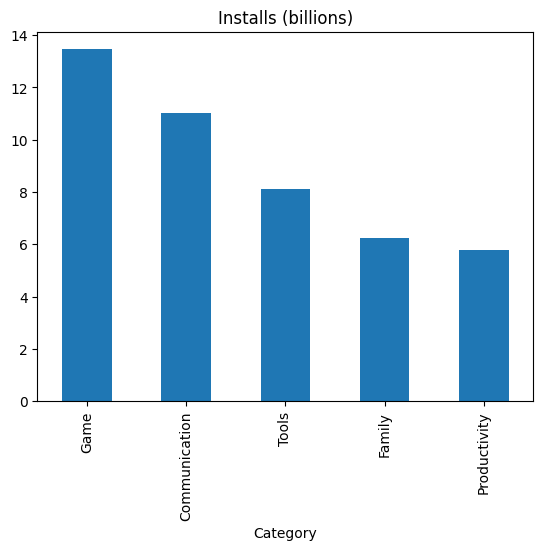

In [27]:
t=df.groupby('Category')['Installs'].sum().sort_values(ascending=False).head(5); print(t)
(t/1e9).plot.bar(title='Installs (billions)'); plt.show()

**Answer:** Top 5 categories by total installs: Game (13.5B), Communication (11.0B), Tools (8.1B), Family (6.2B), Productivity (5.8B).

## Advanced questions

### Q1. Top 10 highest-rated apps vs reviews and installs

In [28]:
cols=['App','Category','Rating','Reviews','Installs']
print('Rating only:'); print(rated.sort_values(['Rating','Reviews'], ascending=False).head(10)[cols])
print('\nWith >= 1000 reviews:'); print(rated[rated['Reviews']>=1000].sort_values(['Rating','Reviews'], ascending=False).head(10)[cols])

Rating only:
                                                    App            Category  Rating  Reviews  Installs
7547                                         Ríos de Fe           Lifestyle     5.0      141      1000
4134  FD Calculator (EMI, SIP, RD & Loan Eligilibility)             Finance     5.0      104      1000
6774                                         Oración CX           Lifestyle     5.0      103      5000
1443                     Barisal University App-BU Face              Family     5.0      100      1000
6080                                         Master E.K              Family     5.0       90      1000
2091                                            CL REPL               Tools     5.0       47      1000
255                                              AJ Cam         Photography     5.0       44       100
249    AI Today : Artificial Intelligence News & AI 101  News And Magazines     5.0       43       100
2179                        CS & IT Interview Questions     

**Answer:** By rating alone the top 10 are all 5.0-star apps, but they are tiny (271 apps score 5.0; median only 4 reviews). Using a credibility filter (>= 1,000 reviews) the leaders are 4.9-star apps such as JW Library, Six Pack in 30 Days - Abs Workout, Tickets + PDA 2018 Exam with hundreds of thousands of reviews.

### Q2. Trend and seasonality of updates

Last Updated
2010       1
2011      15
2012      26
2013     108
2014     203
2015     448
2016     779
2017    1792
2018    6287
dtype: int64
Last Updated
1      4.9
2      5.4
3      6.6
4      6.0
5      9.6
6     12.1
7     27.0
8     13.3
9      3.2
10     3.9
11     3.8
12     4.3
dtype: float64


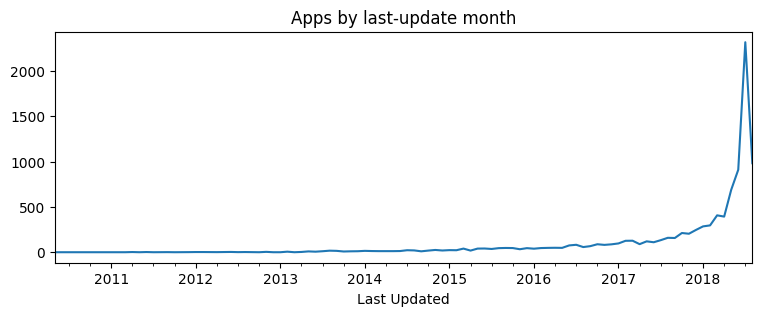

In [29]:
print(df.groupby(df['Last Updated'].dt.year).size())
m=df.groupby(df['Last Updated'].dt.month).size(); print((m/m.sum()*100).round(1))
df.groupby(df['Last Updated'].dt.to_period('M')).size().plot(title='Apps by last-update month', figsize=(9,3)); plt.show()

**Answer:** Update dates are heavily skewed to recent months: 2018 holds 6,287 of 9,659 apps (65%), and July 2018 alone is 27.0% of all last-update dates. June-August = 52%. Because the data is a snapshot (ends 2018-08-08), this shows recency, not true seasonality.

### Q3. Average rating by installs bin

           mean  median  count
Installs                      
1-1K      4.199     4.4   1334
1K-10K    4.031     4.2   1411
10K-100K  4.095     4.2   1552
100K-1M   4.204     4.3   1918
1M-10M    4.271     4.3   1544
10M-100M  4.359     4.4    393
100M+     4.302     4.3     44


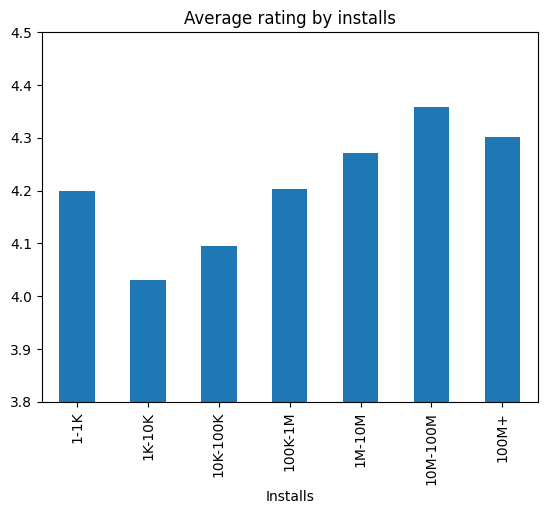

In [30]:
b=pd.cut(rated['Installs'], [-1,0,1e3,1e4,1e5,1e6,1e7,1e8,1e12], labels=['0','1-1K','1K-10K','10K-100K','100K-1M','1M-10M','10M-100M','100M+'])
r=rated.groupby(b, observed=True)['Rating'].agg(['mean','median','count']).round(3); print(r)
r['mean'].plot.bar(ylim=(3.8,4.5), title='Average rating by installs'); plt.show()

**Answer:** Rating is U-shaped: 4.20 (1-1K installs) dips to 4.03 (1K-10K), then climbs steadily to 4.36 at 10M-100M installs (4.30 at 100M+).

### Q4. Sentiment analysis of reviews

In [31]:
print('googleplaystore.csv has no review text - sentiment needs googleplaystore_user_reviews.csv.')
print('Method: merge on App, compute % Positive/Neutral/Negative per rating tier, compare top words.')

googleplaystore.csv has no review text - sentiment needs googleplaystore_user_reviews.csv.
Method: merge on App, compute % Positive/Neutral/Negative per rating tier, compare top words.


**Answer:** NOT computable from this file: googleplaystore.csv has no review text. It needs the second Kaggle file (googleplaystore_user_reviews.csv, columns App / Translated_Review / Sentiment). Method and ready-to-run code are in the Solution Guide.

### Q5. Genre vs user rating (mean and median)

In [32]:
g=rated.groupby('Genres')['Rating'].agg(['count','mean','median']).round(3)
g=g[g['count']>=20].sort_values('mean', ascending=False); print(g.head(8)); print(g.tail(5))

                     count   mean  median
Genres                                   
Events                  45  4.436     4.5
Puzzle                 100  4.370     4.4
Art & Design            55  4.358     4.4
Books & Reference      169  4.345     4.5
Parenting               40  4.340     4.5
Personalization        298  4.332     4.4
Word                    22  4.318     4.3
Education;Education     36  4.294     4.4
                   count   mean  median
Genres                                 
Tools                719  4.040    4.20
Trivia                28  4.039    4.25
Maps & Navigation    118  4.036    4.20
Dating               133  3.980    4.10
Educational           32  3.872    3.95


**Answer:** Highest-rated genres (min 20 apps): Events (4.44), Puzzle (4.37), Art & Design (4.36), Books & Reference (4.34). Lowest: Educational (3.87), Dating (3.98), Maps & Navigation (4.04). Overall mean 4.173.